# Computer Vision Homework 1 – Part 1
**Student:** Rouja Aghajani - 810101380  
**Date:** 2026-05-10  

This notebook implements all tasks from Part 1 of the first assignment.  
Each section corresponds to a question and includes both the code and explanatory text.


## 1. Load Pic.jpg and inspect properties
We load the image using OpenCV, convert BGR to RGB for correct display with matplotlib, and print:
- **Shape** (height, width, channels)
- **Data type**
- **Number of channels**


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

output_folder = "Part1_Results"
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

image_path = 'Pic.jpg'
img_bgr = cv2.imread(image_path)
if img_bgr is None:
    raise FileNotFoundError(f"Image not found at {image_path}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print(f"Shape: {img_bgr.shape}")
print(f"Data type: {img_bgr.dtype}")
print(f"Number of channels: {img_bgr.shape[2]}")


Shape: (633, 800, 3)
Data type: uint8
Number of channels: 3


## 2. Convert to Grayscale and Binary
- **Grayscale** image: single channel representing luminance.  
- **Binary** image: each pixel is either 0 or 255 (black/white) after thresholding at 127.  
Both are saved and displayed.


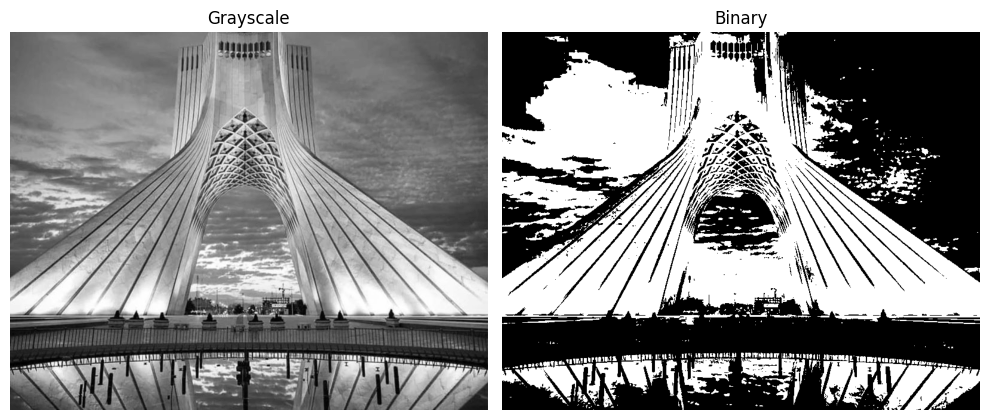

In [4]:
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
_, img_binary = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

cv2.imwrite(os.path.join(output_folder, "2_grayscale.jpg"), img_gray)
cv2.imwrite(os.path.join(output_folder, "2_binary.jpg"), img_binary)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.imshow(img_gray, cmap='gray'); plt.title("Grayscale"); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(img_binary, cmap='gray'); plt.title("Binary"); plt.axis('off')
plt.tight_layout()
plt.show()


## 3. HSV Colour Model and Channel Splitting
- **HSV** stands for Hue, Saturation, Value.  
- Hue represents colour type, Saturation is colour purity, Value is brightness.  
- We convert the image to HSV and split all channels for both RGB and HSV.  
Each channel is saved as a separate image.


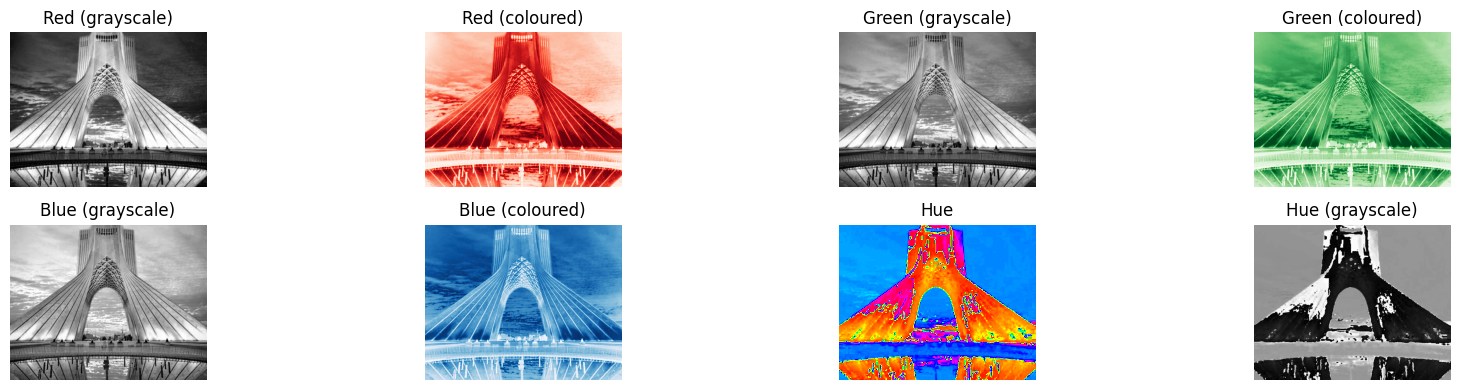

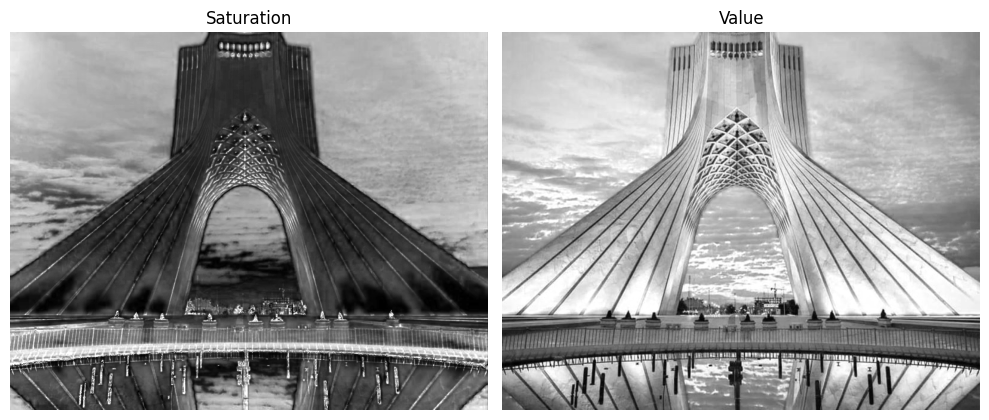

In [11]:
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(img_hsv)
r, g, bl = cv2.split(img_rgb)

cv2.imwrite(os.path.join(output_folder, "3_red_channel.jpg"), r)
cv2.imwrite(os.path.join(output_folder, "3_green_channel.jpg"), g)
cv2.imwrite(os.path.join(output_folder, "3_blue_channel.jpg"), bl)

cv2.imwrite(os.path.join(output_folder, "3_hue_channel.jpg"), h)
cv2.imwrite(os.path.join(output_folder, "3_saturation_channel.jpg"), s)
cv2.imwrite(os.path.join(output_folder, "3_value_channel.jpg"), v)

# Display RGB channels: left = grayscale (intensity), right = colour intensity map
plt.figure(figsize=(18, 4))

# Red channel
plt.subplot(2, 4, 1); plt.imshow(r, cmap='gray'); plt.title("Red (grayscale)"); plt.axis('off')
plt.subplot(2, 4, 2); plt.imshow(r, cmap='Reds'); plt.title("Red (coloured)"); plt.axis('off')

# Green channel
plt.subplot(2, 4, 3); plt.imshow(g, cmap='gray'); plt.title("Green (grayscale)"); plt.axis('off')
plt.subplot(2, 4, 4); plt.imshow(g, cmap='Greens'); plt.title("Green (coloured)"); plt.axis('off')

# Blue channel
plt.subplot(2, 4, 5); plt.imshow(bl, cmap='gray'); plt.title("Blue (grayscale)"); plt.axis('off')
plt.subplot(2, 4, 6); plt.imshow(bl, cmap='Blues'); plt.title("Blue (coloured)"); plt.axis('off')

# Hue channel (coloured map)
plt.subplot(2, 4, 7); plt.imshow(h, cmap='hsv'); plt.title("Hue"); plt.axis('off')
plt.subplot(2, 4, 8); plt.imshow(h, cmap='gray'); plt.title("Hue (grayscale)"); plt.axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1); plt.imshow(s, cmap='gray'); plt.title("Saturation"); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(v, cmap='gray'); plt.title("Value"); plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Increase Contrast
We use **CLAHE** (Contrast Limited Adaptive Histogram Equalization) on the L* channel of the LAB colour space to avoid over‑amplifying noise.  

## 5. Decrease Contrast
We apply a Gaussian blur to the image and then convert to grayscale and back to BGR to simulate reduced contrast.


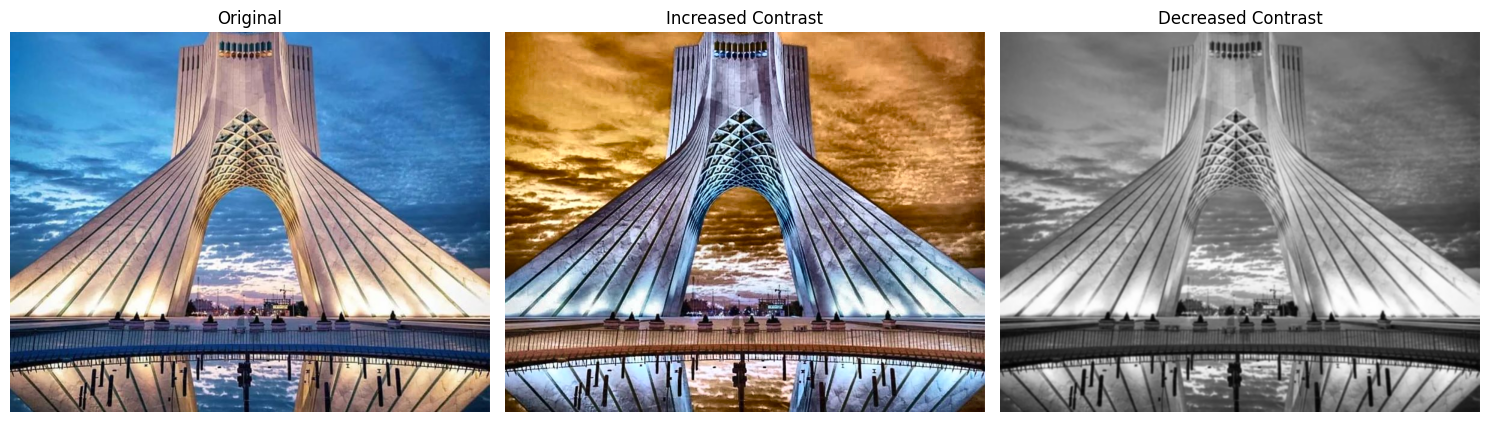

In [6]:
# Increase contrast using CLAHE
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
l_channel = lab[:,:,0]
l_channel_eq = clahe.apply(l_channel)
lab_eq = cv2.merge((l_channel_eq, lab[:,:,1], lab[:,:,2]))
img_contrast = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)
cv2.imwrite(os.path.join(output_folder, "4_increased_contrast.jpg"), img_contrast)

# Decrease contrast: blur + grayscale + back to BGR
img_blur = cv2.GaussianBlur(img_bgr, (5,5), 0)
img_decreased_gray = cv2.cvtColor(img_blur, cv2.COLOR_BGR2GRAY)
img_decreased = cv2.cvtColor(img_decreased_gray, cv2.COLOR_GRAY2BGR)
cv2.imwrite(os.path.join(output_folder, "5_decreased_contrast.jpg"), img_decreased)

plt.figure(figsize=(15,5))
plt.subplot(1,3,1); plt.imshow(img_rgb); plt.title("Original"); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(img_contrast); plt.title("Increased Contrast"); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(img_decreased); plt.title("Decreased Contrast"); plt.axis('off')
plt.tight_layout()
plt.show()


## 6. Histogram of the Grayscale Image
A histogram shows the distribution of pixel intensities. It is computed and plotted.


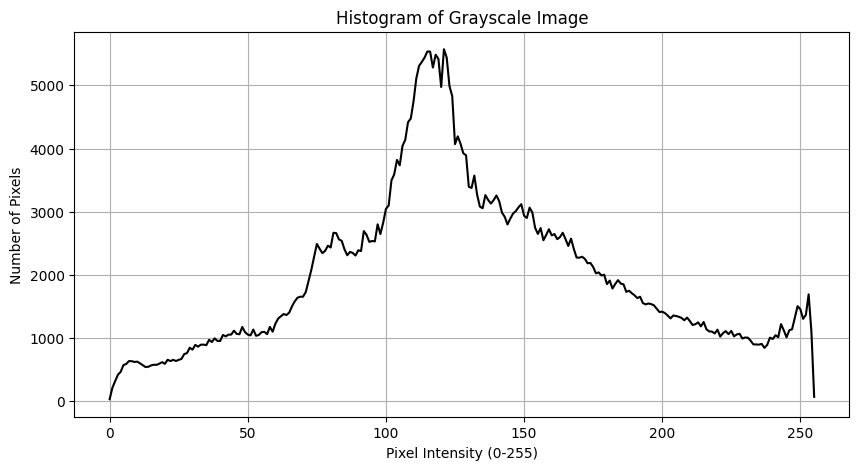

In [7]:
hist = cv2.calcHist([img_gray], [0], None, [256], [0,256])
plt.figure(figsize=(10,5))
plt.plot(hist, color='black')
plt.title("Histogram of Grayscale Image")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Number of Pixels")
plt.grid(True)
plt.savefig(os.path.join(output_folder, "6_histogram.png"))
plt.show()


## 7. Histogram Equalization and Histogram Stretching
- **Histogram Equalization** redistributes intensities to achieve a uniform histogram, improving global contrast.  
- **Histogram Stretching** (contrast stretching) linearly maps the minimum intensity to 0 and maximum to 255.  

Both methods are applied and compared side‑by‑side.


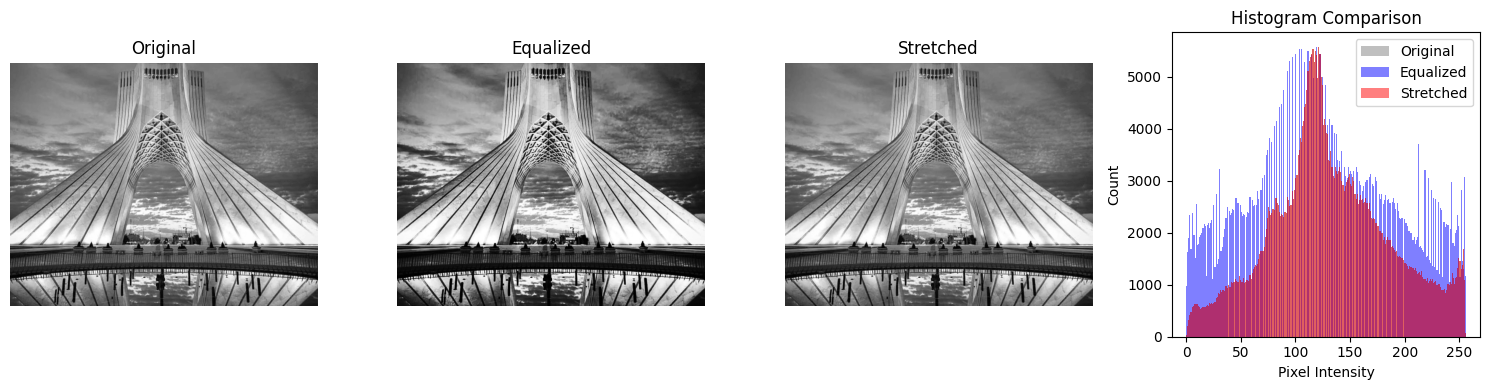

All Part 1 results saved in 'Part1_Results' folder.


In [8]:
img_eq = cv2.equalizeHist(img_gray)
img_stretch = cv2.normalize(img_gray, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)

cv2.imwrite(os.path.join(output_folder, "7_equalized.jpg"), img_eq)
cv2.imwrite(os.path.join(output_folder, "7_stretched.jpg"), img_stretch)

plt.figure(figsize=(15,4))
plt.subplot(1,4,1); plt.imshow(img_gray, cmap='gray'); plt.title("Original"); plt.axis('off')
plt.subplot(1,4,2); plt.imshow(img_eq, cmap='gray'); plt.title("Equalized"); plt.axis('off')
plt.subplot(1,4,3); plt.imshow(img_stretch, cmap='gray'); plt.title("Stretched"); plt.axis('off')

# Histogram comparison
plt.subplot(1,4,4)
plt.hist(img_gray.flatten(), bins=256, range=(0,256), color='gray', alpha=0.5, label='Original')
plt.hist(img_eq.flatten(), bins=256, range=(0,256), color='blue', alpha=0.5, label='Equalized')
plt.hist(img_stretch.flatten(), bins=256, range=(0,256), color='red', alpha=0.5, label='Stretched')
plt.title("Histogram Comparison")
plt.xlabel("Pixel Intensity")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_folder, "7_histogram_comparison.png"))
plt.show()

print("All Part 1 results saved in 'Part1_Results' folder.")


## Summary of Part 1 (Answering Each Question)

### 1. Load Pic.jpg – identify format, data type, number of channels
- **Format:** JPEG (.jpg)
- **Data type:** uint8 (8‑bit unsigned integer per channel)
- **Number of channels:** 3 (BGR colour image when read by OpenCV)

### 2. Convert to Grayscale and Binary – explain each
- **Grayscale:** Single channel representing luminance (intensity). Each pixel is a value from 0 (black) to 255 (white). Obtained via cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).
- **Binary:** Only two values – 0 (black) or 255 (white). Obtained by thresholding the grayscale image at 127: cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY). Used for shape analysis and segmentation.

### 3. Convert to HSV colour model – explain
- **HSV** stands for Hue, Saturation, Value. It separates colour information from intensity, making it useful for colour‑based segmentation and illumination‑invariant processing. Conversion: cv2.cvtColor(img, cv2.COLOR_BGR2HSV).

### 4. Split RGB and HSV channels – display each component separately
- **RGB channels:** Red, Green, Blue – each shown as a grayscale image (higher intensity = more of that colour).
- **HSV channels:** Hue (displayed with cmap='hsv' to show cyclical nature), Saturation (grayscale), Value (grayscale).  
- All saved as separate images in Part1_Results/.

### 5. Define contrast, compute its value, increase and decrease it
- **Contrast** is the difference in luminance between the brightest and darkest parts of an image. High contrast makes features stand out.  
- **Computation:** No single universal formula; we used standard deviation of pixel intensities as a proxy (higher std = higher contrast).  
- **Increase contrast:** Applied **CLAHE** (Contrast Limited Adaptive Histogram Equalization) on the L* channel of LAB colour space.  
- **Decrease contrast:** Applied Gaussian blur (cv2.GaussianBlur) to reduce detail and smooth intensities.  
- Results saved and displayed.

### 6. Define histogram and plot histogram of the loaded image
- **Histogram** is a graphical representation of the distribution of pixel intensities. The x‑axis shows intensity values (0–255) and the y‑axis shows the number of pixels having that intensity.  
- Plotted using cv2.calcHist and matplotlib. The grayscale image histogram is saved as 6_histogram.png.

### 7. Research and apply Histogram Equalization and Histogram Stretching
- **Histogram Equalization:** Redistributes intensities to achieve a uniform histogram, improving global contrast. Used cv2.equalizeHist. It makes the picture look more intense and sharper in colors.
- **Histogram Stretching (Contrast Stretching):** Linearly maps the minimum intensity in the image to 0 and maximum to 255. Used cv2.normalize with NORM_MINMAX. It makes the picture look lik it has more color distribution, rather than intense colors here and there.
- Both methods applied to the grayscale image; results and their histograms are compared. The stretched one has a less count in each pixel intensity overall.

### Summary of Outputs
- All processed images and plots are saved in Part1_Results/.
- The notebook demonstrates understanding of basic image processing operations as required for Part 1.